# 1. Preprocessing

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# static table
cities = pd.read_csv("../data/cities.csv")
stations = pd.read_csv(("../data/stations.csv"))
bikes = pd.read_csv(("../data/bikes.csv"))
bike_types = pd.read_csv(("../data/bike_types.csv"))

# dynamic table
trips = pd.read_csv(("../data/trips_small.csv"))

# Use external data from https://github.com/TUMFTM/european-bike-sharing-dataset/blob/main/sample/city_areas.csv
areas = pd.read_csv("../data/city_areas.csv")


## Util

**Solve this problem first: a bike has trips in multiple cities, but it should belong to one primary city**

Approach: If a bike has trips in multiple cities, it belongs to the city where it has the longest *total trip duration in that city*.

Solving this problem gives a usful dataframe **bike_primary_city** that can be reused in proceeding tasks.

In [2]:
print(f"number of cities in cities.csv: {cities["id"].nunique()}")
print(f"number of cities appeared in trips_small.csv: {trips["city_id"].nunique()}")

number of cities in cities.csv: 267
number of cities appeared in trips_small.csv: 185


In [3]:
print(f"Interesting discovery: bikes.csv has {bikes["id"].nunique()} bikes, but trips_small.csv has only trip records of {trips["bike_id"].nunique()} bikes.")

Interesting discovery: bikes.csv has 88436 bikes, but trips_small.csv has only trip records of 26424 bikes.


Interesting discovery: 
1. Among 267 cities only 185 cities have bike trip records.
2. bikes.csv has 88436 bikes, but trips_small.csv has only trip records of 26424 bikes.


In [4]:
# total trip durations of a bike in every city that it has trips.
tmp = (
    trips.groupby(["city_id", "bike_id"])["duration"]
    .sum().
    reset_index(name="total_duration")
)

# the useful dataframe that can be resued later
bike_primary_city = (tmp.sort_values(by="total_duration", ascending=False)
                     .drop_duplicates(subset="bike_id")
                     [["city_id", "bike_id"]]
                     )

print(f"{tmp.city_id.nunique()} cities has bike trips,")
print(f"but only {bike_primary_city.city_id.nunique()} primary cities are assigned,\nbecause there is one city where all bikes that appeared in that city had a higher total ride duration in other cities.")


185 cities has bike trips,
but only 184 primary cities are assigned,
because there is one city where all bikes that appeared in that city had a higher total ride duration in other cities.


In [5]:
cities_valid = bike_primary_city["city_id"].drop_duplicates()
print(f"number of valid cities: {cities_valid.shape[0]}")

number of valid cities: 184


We are only interested in these 184 cities, for we only have trip data in these cities. (The one non-primary city also excluded.)

## By organisational form: 149 station based, 35 free floating (including hybrid)

In [6]:

city_organization_form = (
    cities.merge(cities_valid, left_on="id", right_on="city_id", how="inner")[["id", "return_to_official_only"]]
    .rename(columns={"id": "city_id"})
)
city_organization_form["return_to_official_only"].value_counts()


return_to_official_only
True     149
False     35
Name: count, dtype: int64

## By propulsion type: 133 conventional, 38 mixed, 13 electric.

We also categorize BSSs by propulsion type: a city with 100% of human powered bikes is a conventional BSS, one with 0% human powered bikes is (fully) electric, while one in between is mixed.


In [7]:
# get its bike_types for every bike. Because bike_types specifies the propulsion type.
bikes = bikes.rename(columns={"id":"bike_id"})
bike_propulsion_type = (
    bikes.merge(bike_types, left_on="bike_type_id", right_on="id")
    .drop(columns=["id"])
    [["bike_id", "bike_type_id", "propulsion_type"]]
)

# check number of bikes with unidentified propsultion types
print(f"There are {bike_propulsion_type.shape[0]} bikes, {bike_propulsion_type["propulsion_type"].isna().sum()} bikes whose propulsion type cannot be identified.")
print("We drop those unidentified bikes, because they are few.")

# drop unidentified bikes
bike_propulsion_type = bike_propulsion_type.dropna(subset=["propulsion_type"])


There are 88436 bikes, 1050 bikes whose propulsion type cannot be identified.
We drop those unidentified bikes, because they are few.


Most of bikes are human powered:

In [8]:
bike_propulsion_type["propulsion_type"].value_counts()


propulsion_type
human              81530
electric_assist     5856
Name: count, dtype: int64

In [9]:
# merge with bike_primary_city
city_bike_propulsion = bike_propulsion_type.merge(bike_primary_city, on="bike_id", how="inner")
city_bike_propulsion.shape

(25833, 4)

Note that all bikes from trips has been assigned with their (primary) cities. But some bikes have NA in propulsion type--those bikes are dropped in bikes_propulsion_type. By inner merge, these bikes are dropped. The resulting city_bike_propulsion has cities with all bikes whose propulsion types are known.
(25833 < 26424)

Final step: calculate the proportion of human-powered bikes and categorize cities by propulsion types into conventional, mixed, electric.

In [10]:
# count the proportion of human powered bikes in each city
tmp = (city_bike_propulsion.assign(is_human=(city_bike_propulsion["propulsion_type"] == "human"))
        .groupby("city_id")["is_human"]
        .mean()
        .reset_index(name="proportion_of_human_powered_bikes")
        )

# define filter
def categorize_propulsion_type(n):
    if n == 1:
        return "conventional"
    elif n == 0:
        return "electric"
    else:
        return "mixed"

# apply filter
tmp["type"] = tmp["proportion_of_human_powered_bikes"].apply(categorize_propulsion_type)

city_propulsion_type = tmp
city_propulsion_type["type"].value_counts()

type
conventional    133
mixed            38
electric         13
Name: count, dtype: int64

## n_bikes in each city

**city_bikes** city_id | n_bikes

In [11]:
city_bikes = (city_bike_propulsion.groupby("city_id")["bike_id"]
              .count()
              .reset_index(name="n_bikes"))


## thus Categorizing BSS by size
Small systems: 10 <= n_bikes <= 100
Medium: 101 <= n_bikes <= 500
Large: 501 <= n_bikes

In [12]:
# define filter
def categorize_by_size(n):
    if n >= 500:
        return "large"
    elif n >= 101:
        return "medium"
    elif n >= 10:
        return "small"
    return None

# apply filter
city_size = city_bikes
city_size["size"] = city_size["n_bikes"].apply(categorize_by_size)

print(f"number of small BSS: {city_size[city_size["size"] == "small"].shape[0]}")
print(f"number of medium BSS: {city_size[city_size["size"] == "medium"].shape[0]}")
print(f"number of large BSS: {city_size[city_size["size"] == "large"].shape[0]}")
print(f"{city_size["size"].isna().sum()} BSSs are too small (<10 bikes), they should be excluded from the analysis.")


number of small BSS: 97
number of medium BSS: 72
number of large BSS: 9
6 BSSs are too small (<10 bikes), they should be excluded from the analysis.


In [13]:
# drop too small BSSs
city_size = city_size.dropna(subset="size")
city_size.shape

(178, 3)

## n_stations in each city

**city_stations:** city_id | n_stations

In [14]:
stations = pd.read_csv("../data/stations.csv")

city_stations = (
    stations.groupby("city_id")["id"]
    .count()
    .reset_index(name="n_stations")
)

In [15]:
city_stations.head()

,city_id,n_stations
0,7,37
1,23,29
2,64,44
3,88,41
4,128,44


## n_racks in each city

We noticed that some special racks has negative values. Using AI to search info: there are two reporting schemes from Nextbike. If special_racak is positive, bike_racks means regular racks; if negative, bike_racks means number of total racks, the "-" sign means reserved for charging e-bikes. 

In [16]:
stations["total_racks"] = np.where(
    stations["special_racks"] < 0,
    stations["bike_racks"],                                      # subtractive: bike_racks is already gross total
    stations["bike_racks"] + stations["special_racks"].fillna(0) # additive: add both
)

# city_bikes we already have, now calculate city_racks
city_racks = (
    stations.groupby("city_id")["total_racks"]
    .sum()
    .reset_index(name="n_racks")
)


## city area

use city_areas.csv from github, meaning cf paper Table 13

**city_area**: city_id 

In [17]:
# get the city area (operational area) in sqare km.

# between two lines of "===" are AI generated code
# ====================================================================================
import pandas as pd
import geopandas as gpd
from shapely import wkt

# Parse geometries from WKT (stripping the "SRID=4326;" prefix)
areas['geometry'] = areas['geom_ewkt'].apply(lambda x: wkt.loads(x.split(';')[-1]))

# Create GeoDataFrame in WGS84
gdf = gpd.GeoDataFrame(areas, geometry='geometry', crs="EPSG:4326")

# Option A: Geodesic area calculation directly in km²
# gdf.to_crs(epsg=6933) is an Equal-Area projection (meters)
gdf_projected = gdf.to_crs(epsg=6933)
gdf['area_sq_km'] = gdf_projected.geometry.area / 1_000_000
# ====================================================================================

city_areas = gdf[["city_id", "area_sq_km"]]


## All in one city level dataframe and valid trip records.

**city_all**: city_id | size | n_stations| n_bikes| n_racks | area | organization type | propulsion type

In [ ]:
city_all = (city_size
      .merge(city_stations, on="city_id")
      .merge(city_organization_form, on="city_id")
      .merge(city_propulsion_type, on="city_id")
      .merge(city_racks, on="city_id")
      .merge(city_areas, on="city_id")
    )

trips_valid = (
    bike_propulsion_type.merge(trips, on="bike_id")
    .dropna(subset="time_start")
)


## Result

After preprocessing, we get two dataframes: **city_all** includes all city-level features that we are intersted in, and **trips_valid** includes trips having known start time and made by bikes whose propulsion types are known. We will use these two dataframes in the next session.

# 2. Descriptive Analysis

In [ ]:
# How many valid BSS? 
print(city_all.shape[0])

# How many valid bikes
print(city_all.n_bikes.sum())

178
25803


In [20]:
# Among all these bikes, how many are human-powered, and how many are electric?
print(city_bike_propulsion[city_bike_propulsion["propulsion_type"] == "human"].shape[0])
print(city_bike_propulsion[city_bike_propulsion["propulsion_type"] == "human"].shape[0] / city_bike_propulsion.shape[0] * 100)


22621
87.56629117795069


In [ ]:
# How many bikes belong to free floating or hybrid BSS, how many belong to station based BSS?
print(f"{city_all[city_all["return_to_official_only"] == True].n_bikes.sum()} bikes belongs to station based BSS.")
print(f"{city_all.n_bikes.sum() - city_all[city_all["return_to_official_only"] == True].n_bikes.sum()} bikes belongs to free floating or hybrid BSS.")

22475 bikes belongs to station based BSS.
3328 bikes belongs to free floating or hybrid BSS.


In [22]:
# How many valid trips? What is the total line-of-flight distance?
trips_valid = (
    bike_propulsion_type.merge(trips, on="bike_id")
)
print(f"Number of valid trips: {trips_valid.shape[0]}")
print(f"Total distance: {trips_valid.distance.sum() / 1000} km")


Number of valid trips: 1159030
Total distance: 2075852.0880000535 km


## Result

we have identified 178 valid cities with 25803 valid bikes. These are cities that have bike trip records and have a fleet size of more than 10 bikes, and bikes that have trip records and identified propulsion type. A majority (87.6% / 22621) of bikes are classic, human-powered bikes, the other (12.4% / 3212) are electric assisted bikes. 87.1% or 22475 bikes belong to station based BSS, the other belong to free floating (including hybrid) BSS. In total, there are 1159030 valid trips with a line-of-flight distance of 2075852 km.

## Indicators

In [ ]:
bss_small = city_all[city_all["size"] == "small"]
bss_medium = city_all[city_all["size"] == "medium"]
bss_large = city_all[city_all["size"] == "large"]

In [24]:
# AI generated code
def get_indicator(bss):
    n_systems = len(bss)
    # Average per-system ratios; zero denominators are excluded as undefined.
    bikes_per_station = bss["n_bikes"].div(bss["n_stations"].replace(0, np.nan))
    bikes_per_rack = bss["n_bikes"].div(bss["n_racks"].replace(0, np.nan))
    bikes_per_sq_km = bss["n_bikes"].div(bss["area_sq_km"].replace(0, np.nan))
    stations_per_sq_km = bss["n_stations"].div(bss["area_sq_km"].replace(0, np.nan))

    return {
        "n_systems": n_systems,
        "avg_bikes_per_station": bikes_per_station.mean(),
        "avg_bikes_per_rack": bikes_per_rack.mean(),
        "avg_bikes_per_sq_km": bikes_per_sq_km.mean(),
        "avg_stations_per_sq_km": stations_per_sq_km.mean(),
        "share_mixed_propulsion_bss_pct": bss["type"].eq("mixed").mean() * 100,
        "share_electric_bss_pct": bss["type"].eq("electric").mean() * 100,
    }

In [25]:
# AI generated code
size_indicators = pd.DataFrame.from_dict(
    {
        "small": get_indicator(bss_small),
        "medium": get_indicator(bss_medium),
        "large": get_indicator(bss_large),
    },
    orient="index",
).rename_axis("size")
size_indicators

,n_systems,avg_bikes_per_station,avg_bikes_per_rack,avg_bikes_per_sq_km,avg_stations_per_sq_km,share_mixed_propulsion_bss_pct,share_electric_bss_pct
size,,,,,,,
small,97,5.758213,1.567236,4.675725,0.844523,20.618557,4.123711
medium,72,14.019689,2.691652,10.623029,1.083457,19.444444,8.333333
large,9,60.083519,8.013733,39.059099,0.764905,22.222222,11.111111


## Visualizations

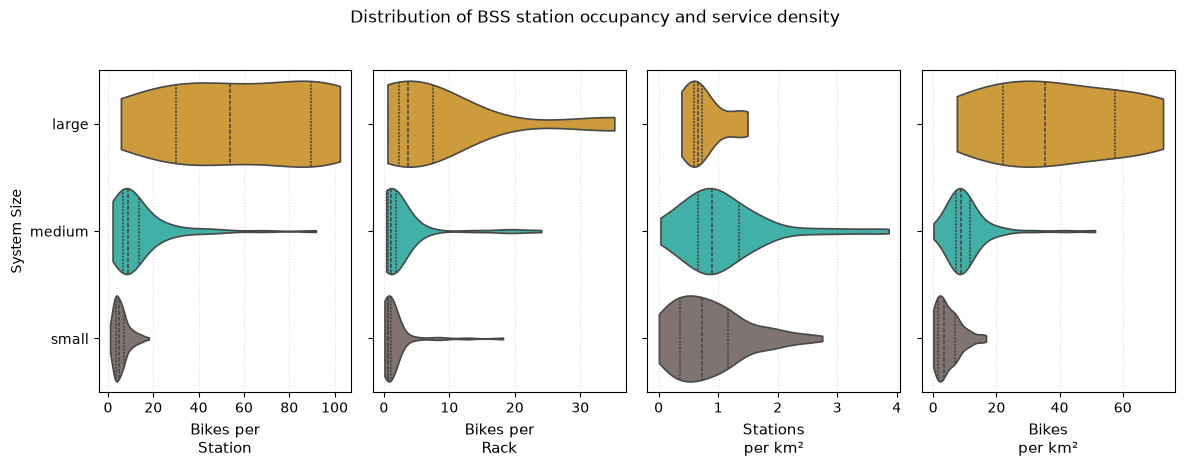

In [ ]:
# Fig 4
size_order = ["large", "medium", "small"]
size_palette = {"large": "#e5a323", "medium": "#2ec4b6", "small": "#81736e"}

plot_data = city_all.assign(
    bikes_per_station=city_all["n_bikes"].div(city_all["n_stations"].replace(0, np.nan)),
    bikes_per_rack=city_all["n_bikes"].div(city_all["n_racks"].replace(0, np.nan)),
    stations_per_sq_km=city_all["n_stations"].div(city_all["area_sq_km"].replace(0, np.nan)),
    bikes_per_sq_km=city_all["n_bikes"].div(city_all["area_sq_km"].replace(0, np.nan)),
).melt(
    id_vars="size",
    value_vars=[
        "bikes_per_station",
        "bikes_per_rack",
        "stations_per_sq_km",
        "bikes_per_sq_km",
    ],
    var_name="indicator",
    value_name="value",
).dropna(subset=["value"])

indicators = [
    ("bikes_per_station", "Bikes per\nStation"),
    ("bikes_per_rack", "Bikes per\nRack"),
    ("stations_per_sq_km", "Stations\nper km²"),
    ("bikes_per_sq_km", "Bikes\nper km²"),
]
fig, axes = plt.subplots(1, len(indicators), figsize=(12, 4.5), sharey=True)

for ax, (indicator, label) in zip(axes, indicators):
    sns.violinplot(
        data=plot_data[plot_data["indicator"] == indicator],
        x="value",
        y="size",
        hue="size",
        order=size_order,
        hue_order=size_order,
        palette=size_palette,
        dodge=False,
        cut=0,
        inner="quart",
        linewidth=1.2,
        legend=False,
        ax=ax,
    )
    ax.set_xlabel(label, fontsize=11)
    ax.set_ylabel("System Size" if ax is axes[0] else "")
    if ax is not axes[0]:
        ax.tick_params(axis="y", labelleft=False)
    ax.grid(axis="x", linestyle=":", alpha=0.45)
    ax.set_axisbelow(True)

fig.suptitle("Distribution of BSS station occupancy and service density", y=1.03)
fig.tight_layout()
# fig.savefig("images/bss_indicators_by_system_size.png", dpi=300, bbox_inches="tight")
plt.show()

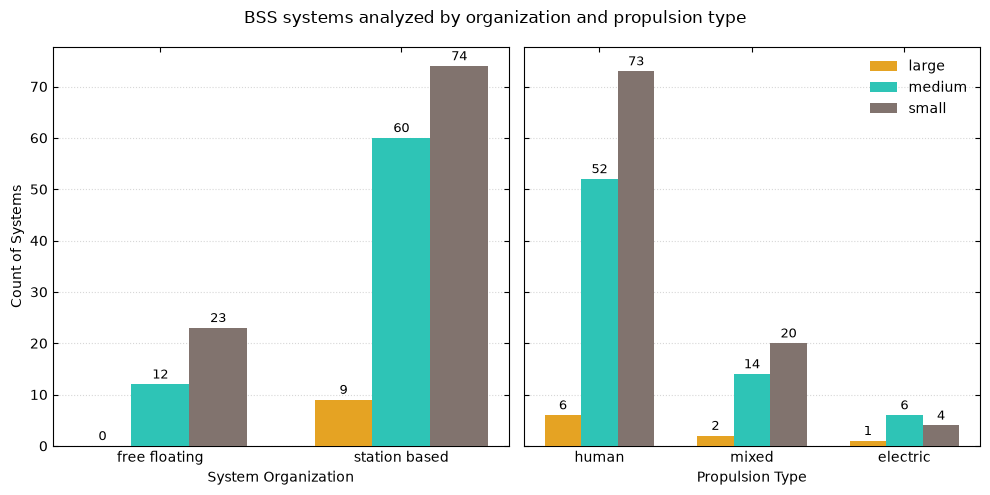

In [ ]:
# Fig 5
size_order = ["large", "medium", "small"]
size_palette = {"large": "#e5a323", "medium": "#2ec4b6", "small": "#81736e"}
size_labels = {"large": "large", "medium": "medium", "small": "small"}

organization_counts = pd.crosstab(
    city_all["return_to_official_only"].map({False: "free floating", True: "station based"}),
    city_all["size"],
).reindex(index=["free floating", "station based"], columns=size_order, fill_value=0)
propulsion_counts = pd.crosstab(
    city_all["type"].replace({"conventional": "human"}),
    city_all["size"],
).reindex(index=["human", "mixed", "electric"], columns=size_order, fill_value=0)

fig, axes = plt.subplots(1, 2, figsize=(10, 5), sharey=True)
bar_width = 0.24

for ax, counts, xlabel in zip(
    axes,
    [organization_counts, propulsion_counts],
    ["System Organization", "Propulsion Type"],
):
    positions = np.arange(len(counts.index))
    for i, size in enumerate(size_order):
        bars = ax.bar(
            positions + (i - 1) * bar_width,
            counts[size].to_numpy(),
            width=bar_width,
            label=size_labels[size],
            color=size_palette[size],
            zorder=3,
        )
        ax.bar_label(bars, padding=2, fontsize=9)

    ax.set_xticks(positions, counts.index)
    ax.set_xlabel(xlabel)
    ax.grid(axis="y", linestyle=":", alpha=0.5, zorder=0)
    ax.set_axisbelow(True)
    ax.tick_params(direction="in", top=True, right=True)

axes[0].set_ylabel("Count of Systems")
axes[1].legend(title=None, frameon=False, loc="upper right")
fig.suptitle("BSS systems analyzed by organization and propulsion type")
fig.tight_layout()
# fig.savefig("images/bss_system_counts_by_category.png", dpi=300, bbox_inches="tight")
plt.show()

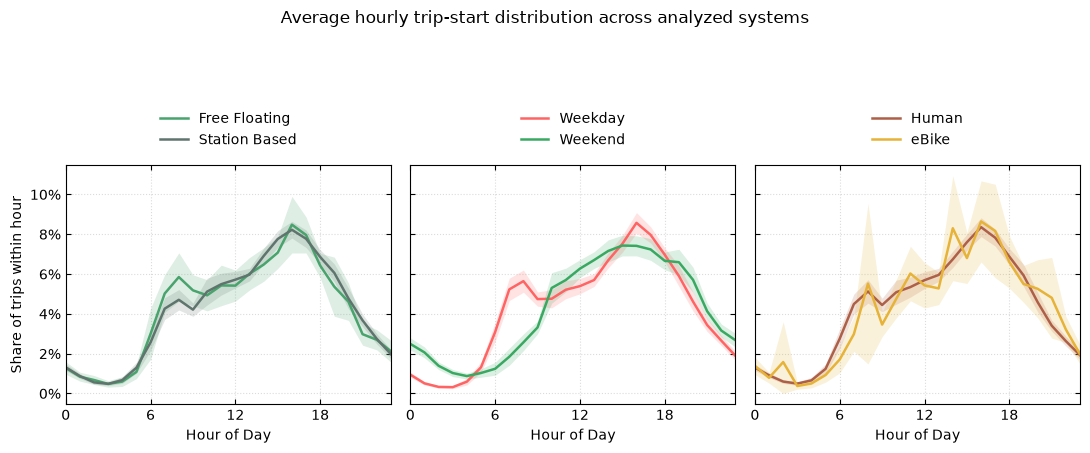

In [ ]:
from matplotlib.ticker import PercentFormatter

# Restrict temporal profiles to the systems included in df and trips with known propulsion.
temporal_trips = (
    trips.merge(
        bike_propulsion_type[["bike_id", "propulsion_type"]],
        on="bike_id",
        how="inner",
    )
    .merge(city_all[["city_id", "return_to_official_only"]], on="city_id", how="inner")
    .merge(
        cities[["id", "timezone"]].rename(columns={"id": "city_id"}),
        on="city_id",
        how="left",
    )
)
if temporal_trips["timezone"].isna().any():
    raise ValueError("A trip city is missing its timezone.")

temporal_trips["hour"] = 0
temporal_trips["day_type"] = ""
for timezone, row_indices in temporal_trips.groupby("timezone").groups.items():
    local_time = pd.to_datetime(
        temporal_trips.loc[row_indices, "time_start"], unit="s", utc=True
    ).dt.tz_convert(timezone)
    temporal_trips.loc[row_indices, "hour"] = local_time.dt.hour.to_numpy()
    temporal_trips.loc[row_indices, "day_type"] = np.where(
        local_time.dt.day_of_week.to_numpy() < 5, "Weekday", "Weekend"
    )

temporal_trips["organization"] = temporal_trips["return_to_official_only"].map(
    {False: "Free Floating", True: "Station Based"}
)
temporal_trips["propulsion"] = temporal_trips["propulsion_type"].map(
    {"human": "Human", "electric_assist": "eBike"}
)


def hourly_mean_ci(group):
    counts = (
        group.groupby(["city_id", "hour"])
        .size()
        .unstack(fill_value=0)
        .reindex(columns=range(24), fill_value=0)
    )
    system_shares = counts.div(counts.sum(axis=1), axis=0)
    mean = system_shares.mean(axis=0).to_numpy()
    margin = (1.96 * system_shares.sem(axis=0).fillna(0)).to_numpy()
    return mean, margin


panels = [
    (
        "organization",
        [("Free Floating", "#48a36c"), ("Station Based", "#60746e")],
    ),
    ("day_type", [("Weekday", "#ff6464"), ("Weekend", "#39a962")]),
    ("propulsion", [("Human", "#ad6047"), ("eBike", "#e6b338")]),
]
fig, axes = plt.subplots(1, 3, figsize=(11, 4), sharey=True)
hours = np.arange(24)

for ax, (group_column, categories) in zip(axes, panels):
    for category, color in categories:
        mean, margin = hourly_mean_ci(
            temporal_trips[temporal_trips[group_column] == category]
        )
        ax.plot(hours, mean, color=color, linewidth=1.8, label=category)
        ax.fill_between(
            hours,
            np.maximum(mean - margin, 0),
            mean + margin,
            color=color,
            alpha=0.18,
            linewidth=0,
        )

    ax.set_xlim(0, 23)
    ax.set_xticks([0, 6, 12, 18])
    ax.set_xlabel("Hour of Day")
    ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
    ax.grid(linestyle=":", alpha=0.45)
    ax.set_axisbelow(True)
    ax.tick_params(direction="in", top=True, right=True)
    ax.legend(frameon=False, loc="lower center", bbox_to_anchor=(0.5, 1.02))

axes[0].set_ylabel("Share of trips within hour")
fig.suptitle("Average hourly trip-start distribution across analyzed systems", y=1.12)
fig.tight_layout()
fig.savefig("images/bss_temporal_distribution.png", dpi=300, bbox_inches="tight")
plt.show()